# ESAM++ Tiny student - shared layers frozen

Official ESAM++ recipe. Same teacher, same frames, same split, same 110 minute budget as exp1, but every shared layer (super point pooling, query decoder, merge head) stays frozen with its published ESAM-E weights and only the TinyExpert backbone is trained. The pretrained decoder is then never dragged away by a random backbone, which is the hypothesis this experiment tests.

Everything below is read from `experiments/exp2_frozen_shared/results/`.


In [1]:
# ============================================================
# 1. METRICS
# ============================================================
import json
from pathlib import Path

RESULTS = Path(r'D:\ESAM_Work') / 'experiments' / 'exp2_frozen_shared' / 'results'

student = json.loads((RESULTS / 'student_ap.json').read_text())
distill = json.loads((RESULTS / 'distill_metrics.json').read_text())
teacher = json.loads((RESULTS / 'teacher_metrics.json').read_text())

print('teacher (ESAM-E) on the validation frames:', teacher['teacher_ap_val'])
print('student                              :', student)
print('best validation loss                 :', round(distill['best_val_loss'], 4))
print('steps / minutes                      :', distill['steps'], round(distill['train_minutes'], 1))
print('trainable tensors                    :', distill.get('trainable_tensors'))
print('frozen shared layers                 :', distill.get('frozen_shared'))
print('targets                              :', distill.get('target'))


teacher (ESAM-E) on the validation frames: {'AP': 0.03201509867846464, 'AP50': 0.054653140304581016, 'AP25': 0.07298618344957553, 'frames': 40}
student                              : {'AP': 0.0021358437577015717, 'AP50': 0.006512552090797106, 'AP25': 0.017674483215154652, 'num_pred': 100, 'num_gt': 267, 'frames': 40}
best validation loss                 : 1.0738
steps / minutes                      : 57814 110.2
trainable tensors                    : 153
frozen shared layers                 : True
targets                              : teacher


In [2]:
# ============================================================
# 2. LOSS HISTORY
# ============================================================
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

history = distill.get('history', [])
losses = [h['loss'] for h in history if 'loss' in h]
validations = [(h['step'], h['val_loss']) for h in history if 'val_loss' in h]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(losses, label='training loss')
ax.set_xlabel('logged step')
ax.set_ylabel('loss')
if validations:
    ax2 = ax.twinx()
    ax2.plot([s for s, _ in validations], [v for _, v in validations],
             color='tab:orange', label='validation loss')
    ax2.set_ylabel('validation loss')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / 'loss_history.png', dpi=120)
plt.show()


C:\Users\aimen\AppData\Local\Temp\ipykernel_16320\583395867.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


teacher_preview_frame000.png


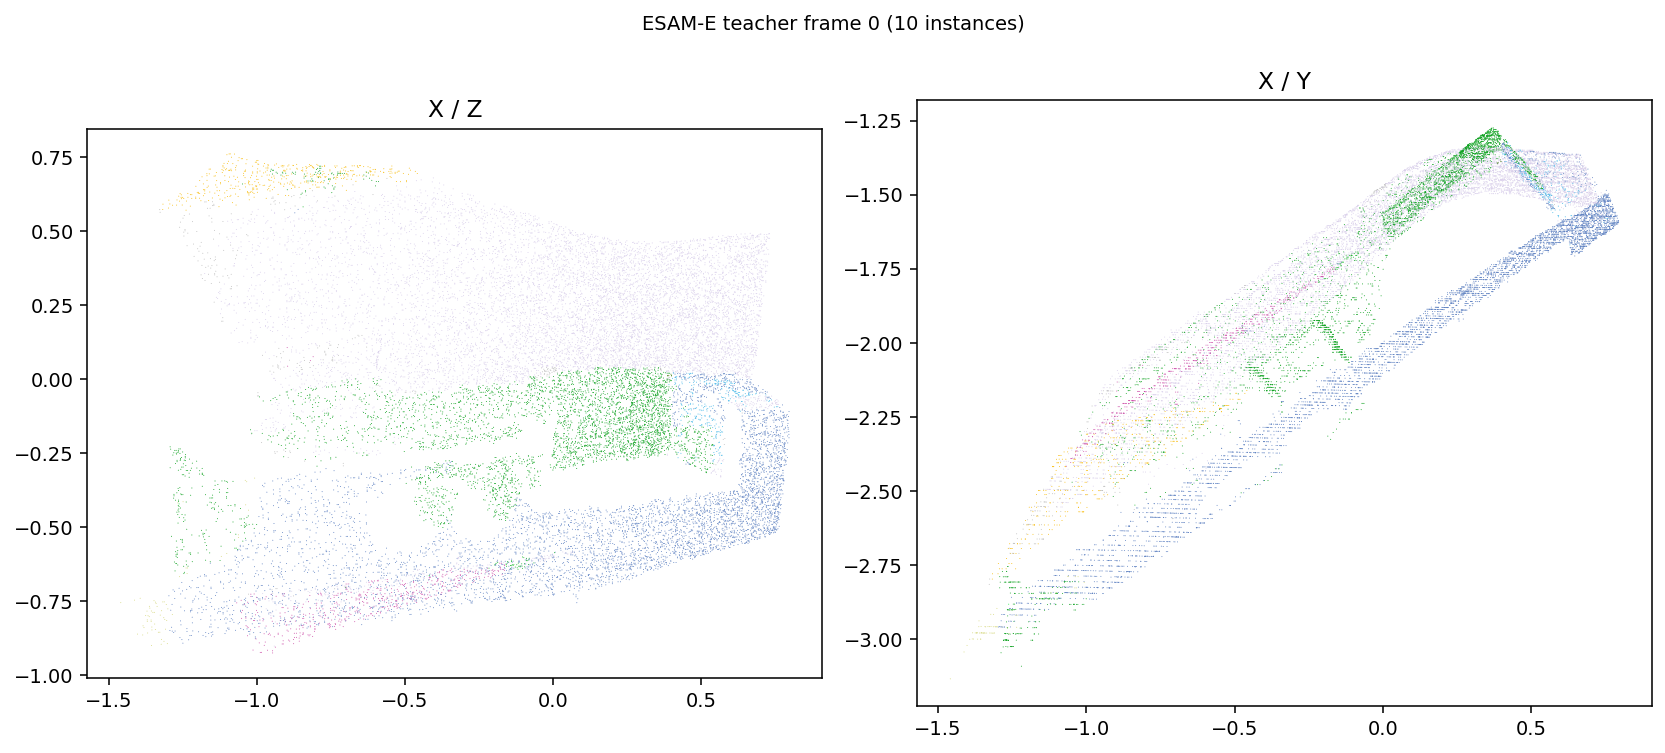

student_preview.png


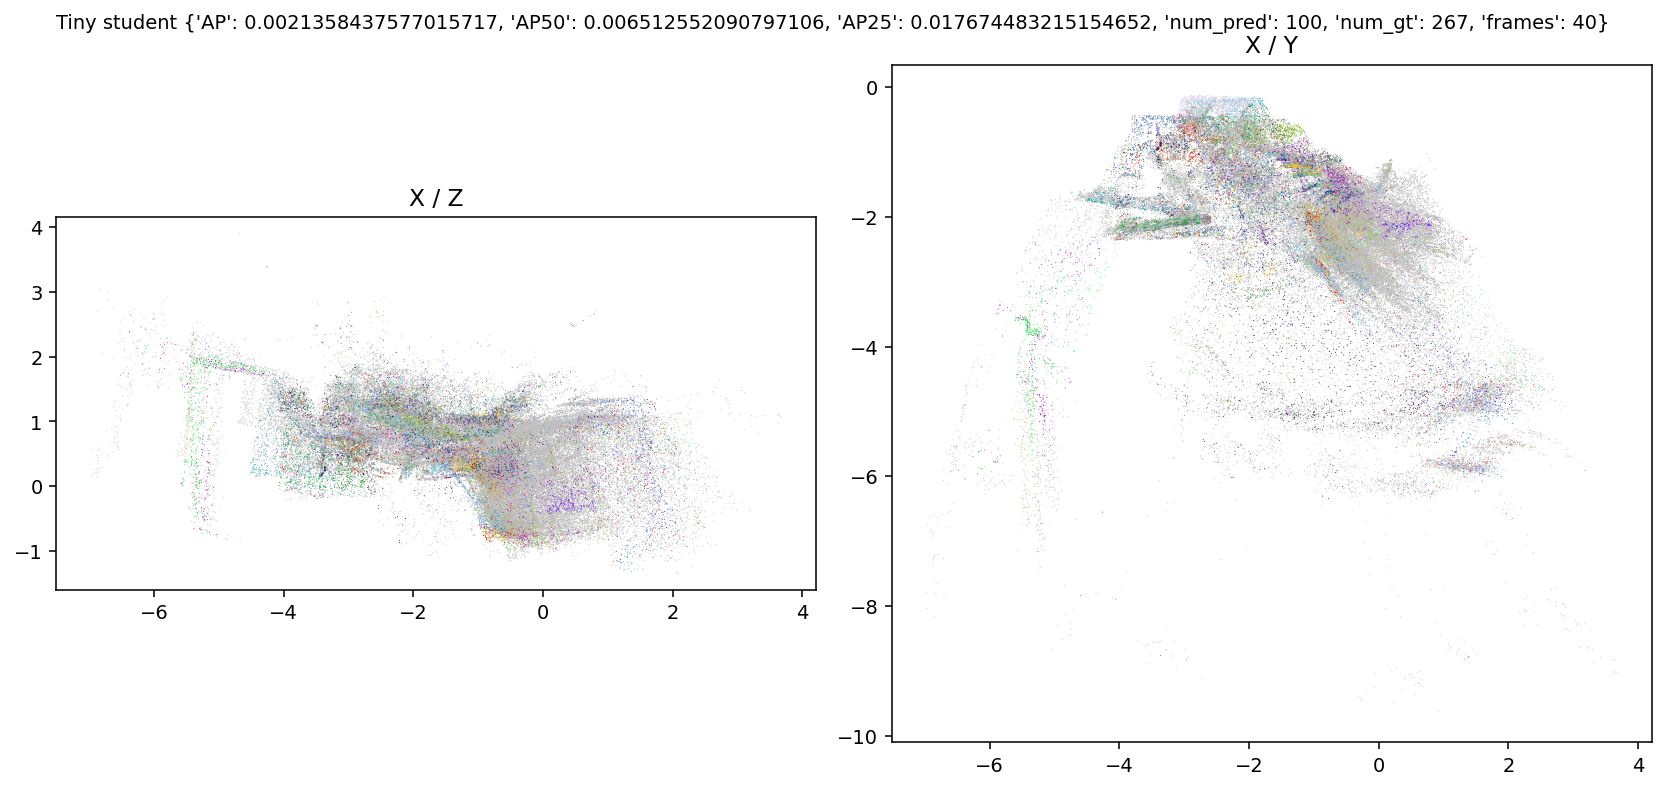

In [3]:
# ============================================================
# 3. PREDICTED INSTANCES
# ============================================================
from IPython.display import Image, display

for name in ('teacher_preview_frame000.png', 'student_preview.png'):
    path = RESULTS / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))


In [4]:
# ============================================================
# 4. EXPORTED POINT CLOUD
# ============================================================
import numpy as np

path = RESULTS / 'student_val.ply'
raw = path.read_bytes()
end = raw.index(b'end_header\n') + len(b'end_header\n')
vertices = int([l for l in raw[:end].decode().splitlines()
                 if l.startswith('element vertex')][0].split()[-1])
record = np.frombuffer(raw[end:], dtype=[('x', '<f4'), ('y', '<f4'), ('z', '<f4'),
                                         ('r', 'u1'), ('g', 'u1'), ('b', 'u1')])
colors = np.stack([record['r'], record['g'], record['b']], axis=1)
unique, counts = np.unique(colors, axis=0, return_counts=True)

print('vertices        :', vertices)
print('instance colours:', len(unique))
print('largest 3 colours cover %.1f %% of the points' %
      (100 * np.sort(counts)[::-1][:3].sum() / vertices))
print('bbox            : x', record['x'].min().round(2), record['x'].max().round(2),
      '| y', record['y'].min().round(2), record['y'].max().round(2),
      '| z', record['z'].min().round(2), record['z'].max().round(2))


vertices        : 800000
instance colours: 94
largest 3 colours cover 74.1 % of the points
bbox            : x -7.3 3.72 | y -9.81 -0.12 | z -1.38 3.89
